In [2]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

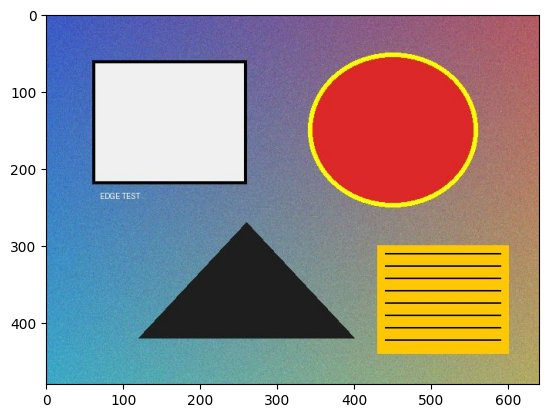

In [3]:
image_path = Path.cwd() / "Photo.jpg"
img = Image.open(image_path).convert("RGB")
img=np.array(img)
plt.imshow(img)

(480, 640)


(np.float64(-0.5), np.float64(639.5), np.float64(479.5), np.float64(-0.5))

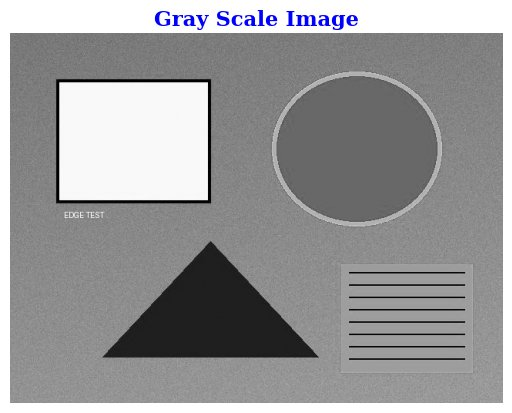

In [22]:
#Convert image to gray scale
img_gray = np.mean(img,axis=2)
print(img_gray.shape) #HW
plt.imshow(img_gray, cmap="gray")
title_style = dict(size=15, color="blue", weight="bold",family="serif")
plt.title("Gray Scale Image", **title_style)
plt.axis("off")

Text(0.5, 1.0, 'Blurred Image')

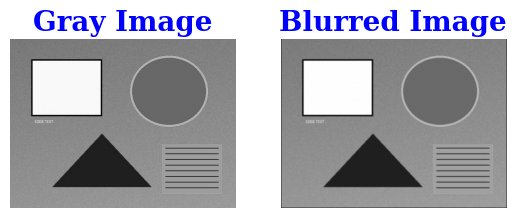

In [20]:
#Blur image
kernel = np.ones((3,3))/9
h,w = img_gray.shape  #to know the height and width of the image
img_blur = np.zeros((h,w))
for i in range(1,h-1):
    for j in range(1,w-1):
        img_blur[i,j] = np.sum(img_gray[i-1:i+2,j-1:j+2]*kernel)  #Pixel in row i and column j = sum of the product of the kernel and the 3x3 neighborhood of the pixel
plt.subplot(1,2,1)
plt.imshow(img_gray, cmap="gray")
plt.axis("off")
plt.title("Gray Image", **title_style)
plt.subplot(1,2,2)
plt.imshow(img_blur, cmap="gray")
plt.axis("off")
plt.title("Blurred Image", **title_style)

Text(0.5, 1.0, 'Sharpened Image')

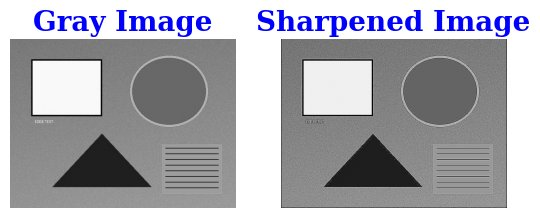

In [21]:
#sharpen image
kernel = np.array([[0,-1,0],
                   [-1,5,-1],
                   [0,-1,0]])   #sum of the kernel = 1 as brightness of the image should not change
h,w =img_gray.shape  #to know the height and width of the image
img_sharpen = np.zeros((h,w))
for i in range(1,h-1):  
    for j in range(1,w-1):
        img_sharpen[i,j] = np.sum(img_gray[i-1:i+2,j-1:j+2]*kernel)  #Pixel in row i and column j = sum of the product of the kernel and the 3x3 neighborhood of the pixel
img_sharpen = np.clip(img_sharpen, 0,255)  #to make sure that the pixel values are in the range of 0-255
plt.subplot(1,2,1)
plt.imshow(img_gray, cmap="gray")
plt.axis("off")
plt.title("Gray Image",**title_style)
plt.subplot(1,2,2)
plt.imshow(img_sharpen, cmap="gray")
plt.axis("off")
plt.title("Sharpened Image",**title_style)

Text(0.5, 1.0, 'Edge Detected Image')

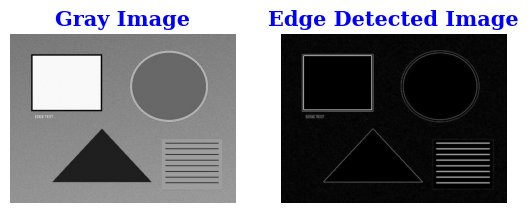

In [23]:
#Edge Detection
Kx=np.array([[-1,0,1],
             [-2,0,2],
             [-1,0,1]])  #Sobel operator for edge detection in the x-direction must sum to 0
Ky=np.array([[-1,-2,-1],
             [0,0,0],
             [1,2,1]])  #Sobel operator for edge detection in the y-direction
edge_sobel = np.zeros((h,w))
for i in range(1,h-1):
    for j in range(1,w-1):
        Gx = np.sum(img_gray[i-1:i+2,j-1:j+2]*Kx)  #Gradient in the x-direction
        Gy = np.sum(img_gray[i-1:i+2,j-1:j+2]*Ky)  #Gradient in the y-direction
        edge_sobel[i,j] = np.sqrt(Gx**2 + Gy**2)  #Magnitude of the gradient
edge_sobel = edge_sobel/np.max(edge_sobel)  #to make sure that the pixel values are in the range of 0-1
plt.subplot(1,2,1)
plt.imshow(img_gray, cmap="gray")
plt.axis("off")
plt.title("Gray Image",**title_style)
plt.subplot(1,2,2)
plt.imshow(edge_sobel, cmap="gray")
plt.axis("off")
plt.title("Edge Detected Image",**title_style)